# Hotel Cancellation Risk Scoring: 데이터 누수(Data Leakage) 통제 기반의 예약 취소 예측

## [01_eda_baseline.ipynb] 목표
1. 원본 데이터셋의 구조 파악. 결측치, 타겟변수(is_canceled) 클래스 불균형 확인
2. 도메인 기반 예약 취소 영향요인 가설 설정
3. 피처 유효성 검토
4. 데이터 특성을 고려한 베이스라인 생성
    - 정형 데이터 이진분류에서 피처 영향도 해석이 직관적인 로지스틱 회귀로 성능 기준선 도출

## 1. 데이터 개요

### 1-1. 데이터 기본 정보
- 데이터 출처 : hotel booking demand datasets (https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)
- 수집 기간 : 2015년 7월 1일 ~ 2017년 8월 31일 (약 2년 2개월)
- 데이터 규모 : 119,390건의 예약 기록, 32개 피처
- 대상 호텔 유형
    - `Resort Hotel`: 포르투갈 남부 알가르브(Algarve) 휴양지에 위치한 리조트 호텔
    - `City Hotel` : 리스본(Lisbon) 도심에 위치한 비즈니스/관광 호텔
- 타겟변수 : 고객의 최종 예약 취소 여부 (`is_canceled`)
    - 0 : 정상 체크인, 투숙 완료
    - 1 : 예약 취소 또는 No-Show


### 1-2. 비즈니스 문제 정의
- 호텔은 예약 취소, 노쇼로 빈 방이 생기는 것이 손실이 된다. 취소될 예약을 예측하여 손실을 줄이는 조치를 취하고자 한다. (빈 객실, 오버부킹 판단)

## 2. 데이터 탐색

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import train_test_split

from src.data import (TARGET, LEAKY_COLS, load_data, summarize, target_ratio,
                      single_feature_auc, arrival_date, duplicate_group_id, drop_leaky, split_xy)
from src.model import make_model, evaluate, compare, top_coefficients

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 50)
SEED = 42

In [2]:
df = load_data()
print(f"행 : {df.shape[0]:,} / 열 : {df.shape[1]}")
df.head()

행 : 119,390 / 열 : 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
summarize(df)

,dtype,n_missing,missing_pct,n_unique,example
hotel,str,0,0.00,2,Resort Hotel
is_canceled,int64,0,0.00,2,0
lead_time,int64,0,0.00,479,342
arrival_date_year,int64,0,0.00,3,2015
arrival_date_month,str,0,0.00,12,July
arrival_date_week_number,int64,0,0.00,53,27
arrival_date_day_of_month,int64,0,0.00,31,1
stays_in_weekend_nights,int64,0,0.00,17,0
stays_in_week_nights,int64,0,0.00,35,0
adults,int64,0,0.00,14,2


In [4]:
# 고윳값 확인
df["reservation_status"].unique()

<StringArray>
['Check-Out', 'Canceled', 'No-Show']
Length: 3, dtype: str

(1) 결측치
  - `company` : 94.31%가 비어있음. 회사(기업)예약이 아닌 개인 예약이 대부분이라는 의미 => 컬럼 삭제 or 이진 피처로 축소
  - `agent` : agent를 통하지 않은 개인의 직접 예약이 13.69%인 것으로 보임.
  - `country` : 0.41%로 결측치가 미미하여 최빈값으로 처리 예정

(2) 데이터 타입
  - `children` : 정수형 변환 필요
  - `reservation_status_date` : 날짜 데이터로 변환

(3) 인코딩
  - 범주형 변수의 고윳값이 한 자리 수인 피처는 원-핫 인코딩 처리
    - hotel
    - deposit_type
    - customer_type
    - meal
    - distribution_channel
    - market_segment

(4) 데이터 누수
  -  `reservation_status` : 고윳값 확인해보니 예약 상태를 그대로 보여주어 타겟 누수 컬럼으로 판단. 제거 필요



## 3. 타겟 변수 분포

### 3-1. 호텔 유형별 취소율 격차 확인

In [5]:
target_ratio(df)

,count,ratio
is_canceled,,
0,75166,0.6296
1,44224,0.3704


,hotel,예약수,예약비중(%),취소율(%)
0,City Hotel,79330,66.4%,41.7%
1,Resort Hotel,40060,33.6%,27.8%


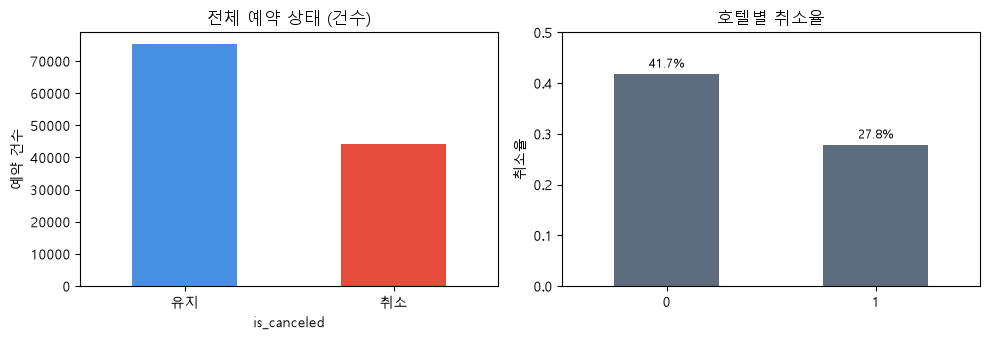

In [7]:
# 호텔별 집계
by_hotel = df.groupby("hotel")[TARGET].agg(예약수="size", 취소율="mean").reset_index()

# 퍼센트(%) 컬럼 추가
by_hotel["예약비중(%)"] = (by_hotel["예약수"] / by_hotel["예약수"].sum()) * 100
by_hotel["취소율(%)"] = by_hotel["취소율"] * 100

# 소수점 1자리 포맷팅 및 보기 좋게 정렬
by_hotel_styled = by_hotel[
    ["hotel", "예약수", "예약비중(%)", "취소율(%)"]
].copy()
by_hotel_styled["예약비중(%)"] = by_hotel_styled["예약비중(%)"].map("{:.1f}%".format)
by_hotel_styled["취소율(%)"] = by_hotel_styled["취소율(%)"].map("{:.1f}%".format)

display(by_hotel_styled)




# 시각화
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

# (좌) 전체 예약 상태 (유지 vs 취소)
df[TARGET].map({0: "유지", 1: "취소"}).value_counts().plot.bar(
    ax=axes[0], rot=0, color=["#4A90E2", "#E74C3C"], title="전체 예약 상태 (건수)"
)
axes[0].set_ylabel("예약 건수")

# (우) 호텔 유형별 취소율
bars = by_hotel["취소율"].plot.bar(
    ax=axes[1], rot=0, color="#5D6D7E", title="호텔별 취소율", ylim=(0, 0.5)
)
axes[1].set_ylabel("취소율")

# 막대 위에 취소율 % 수치 표시
for bar in axes[1].patches:
    height = bar.get_height()
    axes[1].annotate(
        f"{height:.1%}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

- 호텔 유형별 취소율 격차 확인 결과
    - 전체 예약 중 City Hotel이 66% 차지. 취소율도 City Hotel(41.7%)이 Resort Hotel(27.8%)보다 약 14% 높음
        - 정답이 약 63 : 37로 다소 불균형하여 정확도만으로는 예측 성능 판단이 어려워 보임.
    - City Hotel은 출장이나 단기 일정이 많아 취소가 잦고, Resort Hotel은 여행계획 때문에 상대적으로 취소 부담이 큰 것으로 보임
    - `hotel`에 따라 예약 취소 성향이 다를 것으로 판단되어 모델링할 때 중요한 변수일 것으로 보임.

### 3-2. 중복 행 점검
- 데이터 컬럼에 각 행을 식별할 만한 고유 id가 없음


In [10]:
print(f"완전 중복 행 수: {df.duplicated().sum():,}건")
print(f"중복 비율: {df.duplicated().mean() * 100:.1f}%")

완전 중복 행 수: 31,994건
중복 비율: 26.8%


- 대량의 중복 행 발견
    - 전체 데이터의 26.8%에 해당하는 31,994건의 완전 중복 행 발견
    - 오류인지 확인 필요

In [13]:
dup_group = duplicate_group_id(df)
is_dup = df.duplicated(keep=False)
group_size = dup_group[is_dup].value_counts()

print(f"완전 중복 행(첫 행 제외): {df.duplicated().sum():,}")
print(f"중복에 걸린 행: {is_dup.sum():,} / 묶음 수: {len(group_size):,}")
print(f"묶음 크기: 중앙값 {group_size.median():.0f}, 최대 {group_size.max()}")

완전 중복 행(첫 행 제외): 31,994
중복에 걸린 행: 40,165 / 묶음 수: 8,171
묶음 크기: 중앙값 2, 최대 180


- 중복에 걸린 행은 원본 1개 + 복사본 n개인 것, 똑같은 행을 그룹으로 묶었을 때 8,171 중복 그룹 확인됨
- 대부분 2개씩 쌍으로 중복되어 있어 데이터에 오류가 있는지 확인 필요
- 최대 180개 행이 통채로 복제되어 있음. 중복된 데이터가 전부 취소나 유지 중 한쪽에 쏠려있다면 취소율 전체가 왜곡되어 있을 가능성 있음
    - 데이터를 분할하여 A/B 테스트 진행하고, 채택된 방식으로 피쳐 엔지니어링 진행 예정
        - A : 중복을 제거 후 일반 분할
        - B : 중복을 유지하고 그룹별로 분할

In [14]:
# 중복행을 단체 예약으로 가정 
dup_profile = pd.DataFrame({
    "단체(Groups) 비율": df["market_segment"].eq("Groups").groupby(is_dup).mean(),
    "일행(Transient-Party) 비율": df["customer_type"].eq("Transient-Party").groupby(is_dup).mean(),
    "Non Refund 비율": df["deposit_type"].eq("Non Refund").groupby(is_dup).mean(),
    "취소율": df[TARGET].groupby(is_dup).mean(),
}).round(3)
dup_profile.index = dup_profile.index.map({False: "중복 아닌 행", True: "중복 행"})
dup_profile.T

,중복 아닌 행,중복 행
단체(Groups) 비율,0.039,0.416
일행(Transient-Party) 비율,0.106,0.416
Non Refund 비율,0.003,0.356
취소율,0.262,0.584


In [15]:
# 가장 큰 묶음 예시
df[dup_group == group_size.idxmax()].head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
60157,City Hotel,1,277,2016,November,46,7,1,2,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,Non Refund,NaN,NaN,0,Transient,100.0,0,0,Canceled,2016-04-04
60158,City Hotel,1,277,2016,November,46,7,1,2,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,Non Refund,NaN,NaN,0,Transient,100.0,0,0,Canceled,2016-04-04
60159,City Hotel,1,277,2016,November,46,7,1,2,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,Non Refund,NaN,NaN,0,Transient,100.0,0,0,Canceled,2016-04-04
60160,City Hotel,1,277,2016,November,46,7,1,2,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,Non Refund,NaN,NaN,0,Transient,100.0,0,0,Canceled,2016-04-04
60161,City Hotel,1,277,2016,November,46,7,1,2,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,Non Refund,NaN,NaN,0,Transient,100.0,0,0,Canceled,2016-04-04
60162,City Hotel,1,277,2016,November,46,7,1,2,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,Non Refund,NaN,NaN,0,Transient,100.0,0,0,Canceled,2016-04-04
60163,City Hotel,1,277,2016,November,46,7,1,2,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,Non Refund,NaN,NaN,0,Transient,100.0,0,0,Canceled,2016-04-04
60164,City Hotel,1,277,2016,November,46,7,1,2,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,Non Refund,NaN,NaN,0,Transient,100.0,0,0,Canceled,2016-04-04
60165,City Hotel,1,277,2016,November,46,7,1,2,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,Non Refund,NaN,NaN,0,Transient,100.0,0,0,Canceled,2016-04-04
60166,City Hotel,1,277,2016,November,46,7,1,2,2,0.0,0,BB,PRT,Groups,TA/TO,0,0,0,A,A,0,Non Refund,NaN,NaN,0,Transient,100.0,0,0,Canceled,2016-04-04


- 예시 확인 결과 단체 일괄 취소 건이 수십 개씩 뭉쳐있어 이 그룹 전체를 한 쪽에 몰아넣지 않으면 모델 성능이 왜곡될 수 있음
    - 중복 행 번호가 나란히 붙어있어 같은 시점에 일괄 등록된 데이터로 보임.
    - 위의 예시는 277일 전, 수십명의 예약을 9달 전에 예약한 단체 예약으로 보임.
    - 타겟 값이 전부 1(취소), 일괄 취소로 보임.
- 데이터 정보를 찾아보니 본 데이터는 공개하면서 고객 이름과 같은 식별 정보를 지워 익명화된 것으로 확인됨
    - 실제 있었던 예약이므로 행을 지우지 않기로 결정.
    - 같은 묶음이 학습과 평가 세트에 나뉘어 들어가지 않도록 해야 함.
    - 평가를 위해 도착일을 기준으로 기간 분할을 하여 같은 묶음이 한 쪽에 모이도록 하기로 함.
    - 일단 베이스라인은 무작위 분할로 측정.

## 4. 데이터 누수 점검
- 1:1 단변량 누수 스캔
    - 컬럼 하나만으로 타겟을 맞힐 수 있는지 확인 (1에 가까우면 의심)

In [16]:
leak_scan = single_feature_auc(df)
leak_scan.head(10)

,column,auc,n_unique
0,reservation_status,1.000000,3
1,reservation_status_date,0.761574,926
2,country,0.700409,177
3,lead_time,0.688212,479
4,deposit_type,0.662360,3
5,total_of_special_requests,0.634556,6
6,market_segment,0.632712,8
7,assigned_room_type,0.602487,12
8,hotel,0.569823,2
9,distribution_channel,0.568960,5


- `reservation_status`는 AUC 1.0으로 명백한 누수열에 해당 → 삭제 필요

### 4-1. `reservation_status` : 예약 상태

In [10]:
pd.crosstab(df['reservation_status'], df[TARGET])

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


### 4-2. `reservation_status_date` : 예약 상태가 마지막으로 바뀐 날짜
- 가설
    - 유지 고객(0) : 호텔에 와서 체크아웃할 때 최종 상태가 찍힌다면, 상태 날짜는 도착일보다 늦을 것이다
    - 취소 고객(1) : 호텔에 가기 전 미리 취소를 하므로 상태 날짜는 무조건 도착일보다 앞설 것이다

In [17]:
gap = (pd.to_datetime(df["reservation_status_date"]) - arrival_date(df)).dt.days # 상태변경일에서 도착 일을 빼고
gap_check = pd.DataFrame({"상태날짜 >= 도착일 비율": (gap >= 0).groupby(df[TARGET]).mean(), # 0과 같거나 크면 도착 당일이거나, 도착한 뒤에 상태가 기록됨(체크아웃 등)
                          "도착일 대비 일수(중앙값)": gap.groupby(df[TARGET]).median()}) # 정상 투숙객과 취소 고객이 도착일 기준 며칠 전후로 상태가 확정되는지 중앙값 확인 
gap_check.index = gap_check.index.map({0: "유지(0)", 1: "취소(1)"})
gap_check

,상태날짜 >= 도착일 비율,도착일 대비 일수(중앙값)
is_canceled,,
유지(0),1.000000,3.0
취소(1),0.047192,-54.0


- 유지 고객(0)은 모두 상태 날짜가 도착일 이후이다.
- 취소 고객(1)은 도착일보다 평균 54일 앞서서 상태 날짜가 찍힌다.
    - 도착일과의 비교만으로 정답이 드러나므로 제거 필요

### 4-3. `assigned_room_type` : 실제 배정된 객실

In [18]:
mismatch = (df["reserved_room_type"] != df["assigned_room_type"]).rename("예약≠배정")
df.groupby(mismatch)[TARGET].agg(예약수="size", 취소율="mean")

,예약수,취소율
예약≠배정,,
False,104473,0.415629
True,14917,0.053764


- 예약≠배정
    - false : 예약한 방과 배정된 방이 같음 (정상 배정)
    - true : 다른 방이 배정됨 -> 방이 바뀐 고객(true)의 취소율은 5%에 그침

- 방 배정은 체크인할 때 일어나는 과정으로, 방이 바뀌었다는 것 자체가 이미 고객이 취소하지 않고 호텔로 찾아왔다는 의미일 것. 예약 시점에는 알 수 없는 정보이므로 제거 필요.
- 만약 예약 단계에서 고객이 방을 직접 변경했다면 예약 정보 자체가 갱신되었을 것임. 예약 정보가 갱신되면 다른 컬럼인 `booking_changes` 숫자가 +1 올라갈 것.

In [19]:
# 방이 바뀌었는데 취소된 5%의 취소 시점 확인
mismatch_canceled = df[
    (df["reserved_room_type"] != df["assigned_room_type"])
    & (df[TARGET] == 1)
]

# 도착 며칠 전에 취소했는지 계산
days_before = (
    arrival_date(mismatch_canceled)
    - pd.to_datetime(mismatch_canceled["reservation_status_date"])
).dt.days

print(days_before.describe())

count    802.000000
mean      14.310474
std       33.319917
min        0.000000
25%        0.000000
50%        1.000000
75%       11.000000
max      263.000000
dtype: float64


- 중앙값이 1, 0~25% 지점이 모두 0으로 대다수가 도착 당일 또는 1일 전에 취소했을 것으로 보임
- 체크인 직전에 방이 변경된 이력을 예약접수 시점의 모델 입력값으로 넣어버리면 이 손님은 나중에 방이 바뀔 것이다!라고 모델에게 말해주는 꼴이므로 누수 열에 해당 -> 제거 필요

### 4-4. 누수 의심 열
- `deposit_type`
    - 가설
        - Refundable : 언제든 취소가 가능하므로 취소율이 높을 것이다.
        - Non Refund : 환불이 불가하므로 취소율이 0에 가까울 것이다.

In [20]:
df.groupby('deposit_type')[TARGET].agg(예약수='size', 취소율='mean')

,예약수,취소율
deposit_type,,
No Deposit,104641,0.283770
Non Refund,14587,0.993624
Refundable,162,0.222222


- 환불 불가인데 취소율이 99%로 비정상적으로 높음
- deposit_type은 고객이 예약을 하는 순간 확정되는 조건으로, 모델 입력 시점에 존재하는 정보이므로 데이터 누수는 아닌 것 같아 일단 보류

### 4-5. 누수 열을 포함하여 성능 확인 후 제거
- 전체 데이터를 8:2로 나누어 로지스틱 회귀로 빠르게 확인

In [ ]:
train_idx, test_idx = train_test_split(df.index, test_size=0.2, stratify=df[TARGET], random_state=SEED) # 전체 데이터에서 취소(1)와 유지(0)의 비율이 훈련셋과 테스트셋에 똑같이 골고루 섞이도록 함

def fit_eval(data):
    X, y = split_xy(data)
    model = make_model(X, LogisticRegression(max_iter=2000))
    model.fit(X.loc[train_idx], y.loc[train_idx])
    return model, evaluate(model, X.loc[test_idx], y.loc[test_idx])

_, leaky_score = fit_eval(df)
print("누수 열 포함 시 ROC-AUC:", round(leaky_score["roc_auc"], 4))

누수 열 포함 시 ROC-AUC: 1.0


In [22]:
df_clean = drop_leaky(df)
print("제거한 열:", LEAKY_COLS)
print("제거 후 shape:", df_clean.shape)

제거한 열: ['reservation_status', 'reservation_status_date', 'assigned_room_type']
제거 후 shape: (119390, 29)


In [23]:
# 누수 제거된 데이터(df_clean)로 모델 학습 및 평가
clean_model, clean_score = fit_eval(df_clean)

# 결과 출력 및 이전 누수 점수와 직접 비교
print("누수 열 포함 시 ROC-AUC:", round(leaky_score["roc_auc"], 4))
print("누수 열 제거 후 ROC-AUC:", round(clean_score["roc_auc"], 4))

누수 열 포함 시 ROC-AUC: 1.0
누수 열 제거 후 ROC-AUC: 0.9084


## 5. 베이스라인

### 5-1. 로지스틱 회귀
- 분할: 층화 무작위 80:20
- 전처리(`src/model.py`)
    - 수치형 : 중앙값 대체 + 표준화
    - 범주형 : 결측치는 새로운 카테고리(missing)로 대체 + 원-핫 인코딩
    - `agent`,`company`는 숫자지만 ID라서 범주형으로 처리
- DummyClassifier와 비교

In [24]:
X, y = split_xy(df_clean)
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

dummy = make_model(X, DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
logreg = make_model(X, LogisticRegression(max_iter=2000)).fit(X_train, y_train)

results = compare({
    "Dummy(다수 클래스)": evaluate(dummy, X_test, y_test),
    "LogReg (누수 열 포함)": leaky_score,
    "LogReg 베이스라인": evaluate(logreg, X_test, y_test),
})
results

,roc_auc,pr_auc,accuracy,precision,recall,f1
Dummy(다수 클래스),0.5000,0.3704,0.6296,0.0000,0.0000,0.0000
LogReg (누수 열 포함),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
LogReg 베이스라인,0.9084,0.8670,0.8285,0.8112,0.6999,0.7515


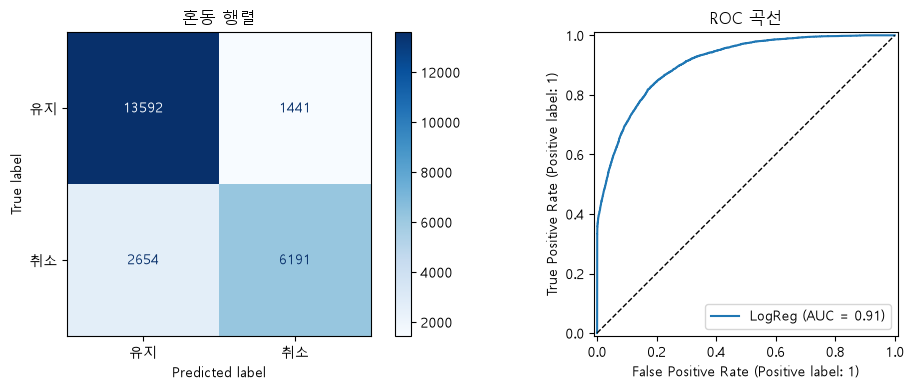

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_estimator(logreg, X_test, y_test, display_labels=["유지", "취소"],
                                      cmap="Blues", ax=axes[0])
axes[0].set_title("혼동 행렬")
RocCurveDisplay.from_estimator(logreg, X_test, y_test, ax=axes[1], name="LogReg")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC 곡선")
plt.tight_layout()

- 혼동행렬
    - 실제 취소(1)인데 유지(0)로 잘못 예측(fn) 2,654건
        - 고객이 올 것을 기대하고 방을 비워뒀는데 노쇼/취소 발생
        - 이 모델은 이 실수를 더 많이 함. 호텔 입장에서 공실 리스크를 방어하고 싶다면 취소 예측에 가중치를 더 주는 방향으로 튜닝해야 함
    - 실제 유지(0)인데 취소(1)로 잘못 예측(fp) 1,441건
        - 고객이 안올줄 알고 오버부킹 받았는데 실제로 손님이 도착. 객실 부족 상황

- ROC 곡선
    - 누수 열을 뺀 순수 데이터로도 로지스틱 회귀가 두 집단을 꽤 분별력 있게 구분하고 있음

### 5-2. 로지스틱 회귀 모델 계수 분석
- 어떤 피처가 예약 취소를 가장 강력하게 유발하는지 그 영향력의 크기와 방향을 확인
    - +방향 : 이 조건을 가질수록 예약 취소 확률이 급격히 높아짐
    - -방향 : 취소 확률을 낮추는 피쳐
    - 막대 길이 : 길이가 길수록 모델이 예측할 때 취소에 미치는 영향력이 강력함

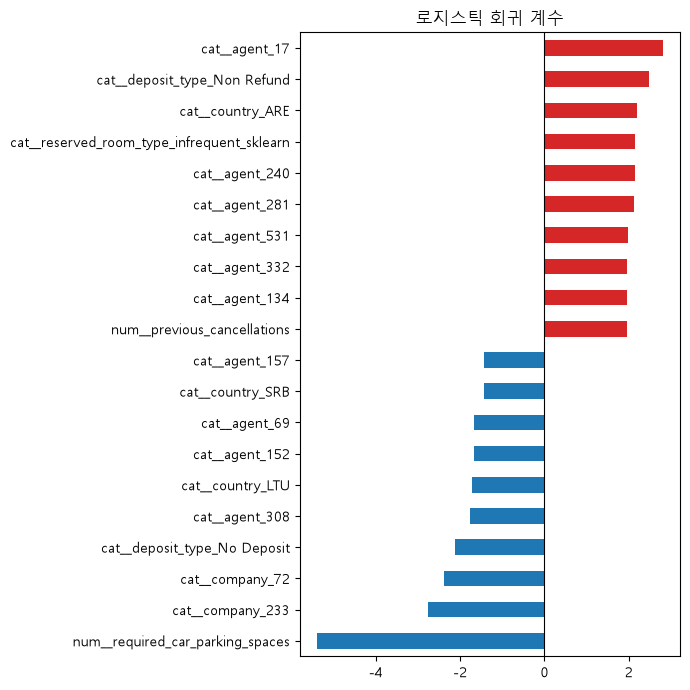

In [27]:
coef = top_coefficients(logreg, n=10)
coef.plot.barh(figsize=(7, 7), color=["tab:blue" if v < 0 else "tab:red" for v in coef])
plt.axvline(0, color="k", lw=0.8)
plt.title("로지스틱 회귀 계수")
plt.tight_layout()

- 특정 여행사(17번, 240번, 281번 등)를 통해 들어온 예약들이 가장 높은 확률로 취소로 이어지고 있음
- 환불 불가조건임에도 취소 쪽으로 높은 가중치가 잡혀있음
- 과거 취소 이력이 영향력이 있음
- 주차 공간 요구 : 주차 공간을 요청한 고객은 취소할 확률이 낮아짐

### 5-3. 중복 행 포함하여 성능 확인

누수 열을 지우면 피처가 같은 행이 더 늘어난다. 피처 기준 묶음 ID로
① 평가 세트 중 학습 세트에 똑같은 행이 있는 비율을 보고, ② 묶음 단위로 나눴을 때(`GroupShuffleSplit`) 점수를 비교한다.

In [28]:
from sklearn.model_selection import GroupShuffleSplit

feat_group = duplicate_group_id(X) # 똑같은 행들을 찾아서 동일한 그룹 id 부여
seen_in_train = feat_group.loc[test_idx].isin(set(feat_group.loc[train_idx])) # 테스트 세트에 있는 문제 중 몇 %가 학습 세트에도 있는지 확인
print(f"무작위 분할: 평가 세트의 {seen_in_train.mean():.1%}가 학습 세트에 똑같은 행이 있음")


# 그룹 분할
g_train, g_test = next(GroupShuffleSplit(test_size=0.2, random_state=SEED).split(X, y, groups=feat_group))
g_train, g_test = X.index[g_train], X.index[g_test]
logreg_g = make_model(X, LogisticRegression(max_iter=2000)).fit(X.loc[g_train], y.loc[g_train])

split_compare = compare({
    "무작위 분할": evaluate(logreg, X_test, y_test),
    "그룹 분할": evaluate(logreg_g, X.loc[g_test], y.loc[g_test]),
})
split_compare

무작위 분할: 평가 세트의 32.8%가 학습 세트에 똑같은 행이 있음


,roc_auc,pr_auc,accuracy,precision,recall,f1
무작위 분할,0.9084,0.8670,0.8285,0.8112,0.6999,0.7515
그룹 분할,0.9056,0.8664,0.8202,0.7928,0.7013,0.7442


- 무작위 분할에서는 평가 세트의 약 1/3이 학습 세트에 똑같은 행을 갖고있음
- 그럼에도 불구하고 로지스틱 회귀의 점수 차이는 작다(ROC-AUC 0.908 → 0.906, F1 0.752 → 0.744)
    - 선형 모델은 개별 행을 외우기 어렵기 때문
    - 트리 계열 모델은 행을 외우기 쉬워 성능 부풀림이 훨씬 클 수 있어 나중에 모델 비교는 묶음 단위 또는 시간 기준 분할로 해야 할 것 같음.

## 6. notebook 마무리

In [20]:
summary = results.loc["LogReg 베이스라인"]
print(f"데이터: {df.shape[0]:,}행 × {df.shape[1]}열, 취소율 {df[TARGET].mean():.1%}")
print(f"제거한 누수 열: {LEAKY_COLS}")
print(f"베이스라인 ROC-AUC {summary.roc_auc:.3f} / PR-AUC {summary.pr_auc:.3f} / "
      f"F1 {summary.f1:.3f} / Accuracy {summary.accuracy:.3f}")

데이터: 119,390행 × 32열, 취소율 37.0%
제거한 누수 열: ['reservation_status', 'reservation_status_date', 'assigned_room_type']
베이스라인 ROC-AUC 0.908 / PR-AUC 0.867 / F1 0.751 / Accuracy 0.829
